# EDA — Clasificación comercial de limón (5 vistas por fruto)

**Objetivo:** conocer los datos *antes* de modelar: ¿están completos, balanceados, bien etiquetados, y libres de atajos (lote/fecha/iluminación) que inflen las métricas?

**Antes de ejecutar:** corre `python src/ingesta.py` (datos reales) o `python scripts/generar_datos_demo.py` + `python src/ingesta.py --raw data/demo/raw --salida data/demo/processed` (datos sintéticos de prueba).

> Con `MODO_DEMO = True` los resultados son de imágenes sintéticas: sirven para validar el notebook, **no** para sacar conclusiones.

In [ ]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import eda
from src.regla_comercial import CALIBRE_EXTRA, CALIBRE_PRIMERA, CALIBRE_SEGUNDA

MODO_DEMO = False
PROC = ROOT / "data" / ("demo/processed" if MODO_DEMO else "processed")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
PAL = {"Extra": "#2e7d32", "Primera": "#7cb342", "Segunda": "#fbc02d", "Tercera": "#ef6c00", "Fabrica": "#7a1f2b"}

## 1. Carga de índices

In [ ]:
frutos = pd.read_csv(PROC / "indice_frutos.csv", dtype={"id_fruto": str, "lote": str, "fecha": str, "vistas_faltantes": str})
imgs   = pd.read_csv(PROC / "indice_imagenes.csv", dtype={"id_fruto": str, "lote": str, "fecha": str})
frutos["cat"] = eda.normalizar_categorias(frutos["categoria_ref"])
print(f"Frutos: {len(frutos)} | Imágenes: {len(imgs)} | Esperadas (5 vistas): {len(frutos)*5}")
frutos.head()

Frutos: 320 | Imágenes: 1600 | Esperadas (5 vistas): 1600


,id_fruto,lote,fecha,calibre_mm_ref,categoria_ref,color_panel,severidad_defecto_panel,vistas_presentes,n_vistas,vistas_faltantes,completo,origen,cat
0,LIM1,L1,20261006,40.8,Fabrica,amarillo,0.50,0;180;270;90;pedunculo,5,NaN,True,ok,Fabrica
1,LIM10,L1,20261006,40.2,Fabrica,verde,0.50,0;180;270;90;pedunculo,5,NaN,True,ok,Fabrica
2,LIM100,L1,20261006,33.1,Fabrica,verde,1.00,0;180;270;90;pedunculo,5,NaN,True,ok,Fabrica
3,LIM101,L2,20261013,39.1,Extra,verde,0.25,0;180;270;90;pedunculo,5,NaN,True,ok,Extra
4,LIM102,L2,20261013,39.1,Extra,verde,0.25,0;180;270;90;pedunculo,5,NaN,True,ok,Extra


## 2. Calidad de datos y etiquetas
Qué buscar: duplicados, etiquetas vacías o inválidas, calibres imposibles, frutos sin imágenes (o imágenes sin etiqueta), capturas incompletas.

In [ ]:
display(eda.resumen_calidad_etiquetas(frutos))
inc = frutos[~frutos["completo"]][["id_fruto", "lote", "fecha", "n_vistas", "vistas_faltantes", "origen"]]
print("\nFrutos con captura incompleta (protocolo: falta 1 vista ecuatorial → 'captura parcial'; falta pedúnculo o >1 ecuatorial → excluir y registrar):")
display(inc)

,conteo
frutos_totales,320
id_fruto_duplicados,0
sin_categoria_ref,0
categoria_invalida,0
sin_calibre_ref,0
calibre_fuera_de_rango(25-60mm),0
frutos_sin_imagenes,0
frutos_sin_etiqueta,0
capturas_incompletas,0



Frutos con captura incompleta (protocolo: falta 1 vista ecuatorial → 'captura parcial'; falta pedúnculo o >1 ecuatorial → excluir y registrar):


,id_fruto,lote,fecha,n_vistas,vistas_faltantes,origen


## 3. Balance de clases vs. cuotas mínimas
Qué buscar: categorías que no llegan a su cuota (250/250/250/200/200). Las minoritarias (Tercera, Fábrica) suelen ser las que faltan.

,frutos,cuota_min,faltan,cumple,%
categoria_ref,,,,,
Extra,109,250,141,False,34.1
Primera,101,250,149,False,31.6
Segunda,0,250,250,False,0.0
Tercera,10,200,190,False,3.1
Fabrica,100,200,100,False,31.2


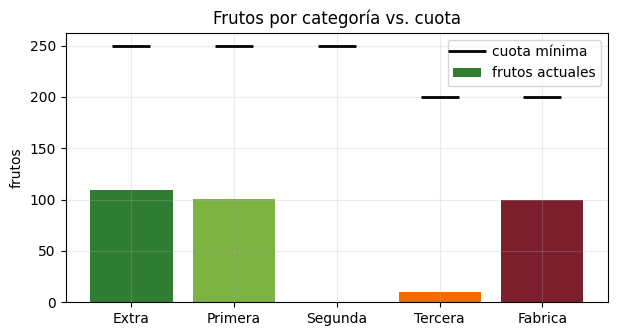

In [ ]:
cuotas = eda.tabla_cuotas(frutos); display(cuotas)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(cuotas.index, cuotas["frutos"], color=[PAL[c] for c in cuotas.index], label="frutos actuales")
ax.plot(cuotas.index, cuotas["cuota_min"], "k_", ms=28, mew=2, label="cuota mínima")
ax.set_ylabel("frutos"); ax.set_title("Frutos por categoría vs. cuota"); ax.legend(); plt.show()

## 4. Cobertura de lotes y fechas
Qué buscar: ≥3 lotes y ≥4 fechas, y que ninguna categoría quede concentrada en un solo lote/fecha.

Lotes: 3 (mín. 3 → OK) | Fechas: 3 (mín. 4 → NO CUMPLE)


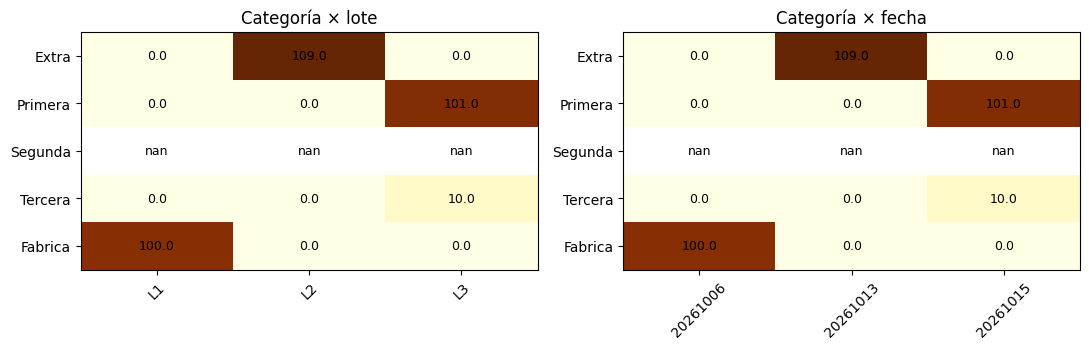

In [ ]:
cob = eda.cobertura_lote_fecha(frutos)
print(f"Lotes: {cob['n_lotes']} (mín. 3 → {'OK' if cob['cumple_lotes'] else 'NO CUMPLE'}) | "
      f"Fechas: {cob['n_fechas']} (mín. 4 → {'OK' if cob['cumple_fechas'] else 'NO CUMPLE'})")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, key, tit in [(axs[0], "cat_x_lote", "Categoría × lote"), (axs[1], "cat_x_fecha", "Categoría × fecha")]:
    t = cob[key]; im = ax.imshow(t.values, cmap="YlOrBr", aspect="auto")
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, rotation=45); ax.set_yticks(range(t.shape[0])); ax.set_yticklabels(t.index)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]): ax.text(j, i, t.values[i, j], ha="center", va="center", fontsize=9)
    ax.set_title(tit); ax.grid(False)
plt.tight_layout(); plt.show()

## 5. Calibre: distribución y consistencia con la categoría
Qué buscar: calibres por categoría coherentes con los umbrales (35 / 37 / 39 mm), etiquetas que contradicen el calibre (Fábrica se excluye: la decide defecto/color) y frutos *fronterizos* (±0,5 mm de un umbral), que son los más sensibles al error de medición (meta MAE ≤ 1,0 mm).

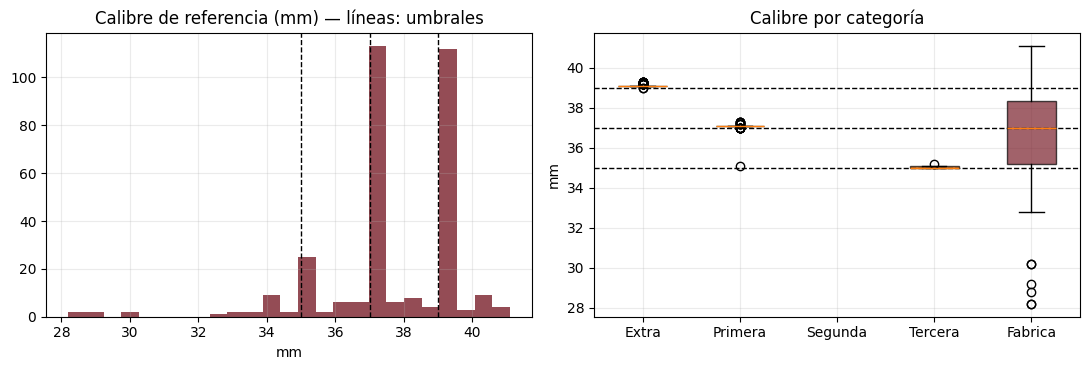

Etiquetas no-Fábrica que contradicen su calibre: 11 (revisar con el panel / recalibrar medición)


,id_fruto,lote,fecha,calibre_mm_ref,cat,cat_segun_calibre
124,LIM210,L3,20261015,35.1,Primera,Segunda
236,LIM311,L3,20261015,35.1,Tercera,Segunda
237,LIM312,L3,20261015,35.0,Tercera,Segunda
238,LIM313,L3,20261015,35.0,Tercera,Segunda
239,LIM314,L3,20261015,35.0,Tercera,Segunda
240,LIM315,L3,20261015,35.0,Tercera,Segunda
241,LIM316,L3,20261015,35.1,Tercera,Segunda
242,LIM317,L3,20261015,35.2,Tercera,Segunda
243,LIM318,L3,20261015,35.0,Tercera,Segunda
244,LIM319,L3,20261015,35.0,Tercera,Segunda


Frutos fronterizos (±0,5 mm de un umbral): 265 = 82.8% del total


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(frutos["calibre_mm_ref"].dropna(), bins=25, color="#7a1f2b", alpha=.8)
for u in (CALIBRE_SEGUNDA, CALIBRE_PRIMERA, CALIBRE_EXTRA): axs[0].axvline(u, color="k", ls="--", lw=1)
axs[0].set_title("Calibre de referencia (mm) — líneas: umbrales"); axs[0].set_xlabel("mm")
data = [frutos.loc[frutos.cat == c, "calibre_mm_ref"].dropna() for c in eda.CATEGORIAS]
bp = axs[1].boxplot(data, labels=eda.CATEGORIAS, patch_artist=True)
for patch, c in zip(bp["boxes"], eda.CATEGORIAS): patch.set_facecolor(PAL[c]); patch.set_alpha(.7)
for u in (CALIBRE_SEGUNDA, CALIBRE_PRIMERA, CALIBRE_EXTRA): axs[1].axhline(u, color="k", ls="--", lw=1)
axs[1].set_title("Calibre por categoría"); axs[1].set_ylabel("mm"); plt.tight_layout(); plt.show()

inco = eda.inconsistencias_calibre_categoria(frutos)
print(f"Etiquetas no-Fábrica que contradicen su calibre: {len(inco)} (revisar con el panel / recalibrar medición)")
display(inco)
fr = eda.fronterizos(frutos, 0.5)
print(f"Frutos fronterizos (±0,5 mm de un umbral): {len(fr)} = {100*len(fr)/len(frutos):.1f}% del total")

## 6. Color y defecto (panel de agrónomos)
Qué buscar: que Fábrica se explique por defecto alto **o** color amarillo, y que las demás categorías tengan defecto bajo. Si estas columnas no existen en tus etiquetas, se omite.

color_panel,amarillo,verde,verde_amarillo
cat,,,
Extra,0.0,109.0,0.0
Primera,0.0,101.0,0.0
Segunda,NaN,NaN,NaN
Tercera,0.0,10.0,0.0
Fabrica,41.0,51.0,8.0


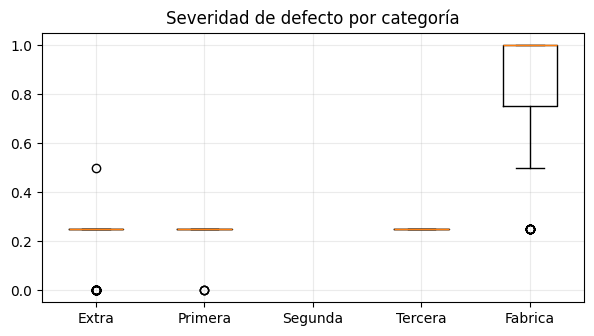

In [ ]:
if {"color_panel", "severidad_defecto_panel"} <= set(frutos.columns):
    display(pd.crosstab(frutos["cat"], frutos["color_panel"]).reindex(eda.CATEGORIAS))
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.boxplot([frutos.loc[frutos.cat == c, "severidad_defecto_panel"].dropna() for c in eda.CATEGORIAS],
               labels=eda.CATEGORIAS)
    ax.set_title("Severidad de defecto por categoría"); plt.show()
else:
    print("Sin columnas de panel de color/defecto: omitido.")

## 7. Calidad de las imágenes
Qué buscar: resolución uniforme, imágenes borrosas (nitidez baja), sobre/sub-exposición, **duplicados exactos** y archivos ilegibles. Con muchas imágenes, usar `max_imgs` para una muestra.

Ilegibles: 0 | Duplicadas: 57
Resoluciones: {(564, 1280): 5, (705, 1600): 10, (720, 1280): 297, (747, 1279): 1, (756, 1600): 30, (818, 1279): 1, (824, 1280): 1, (830, 1279): 1, (849, 1279): 1, (864, 1536): 850, (900, 1600): 136, (960, 1280): 203, (1200, 1600): 60, (1600, 900): 4}


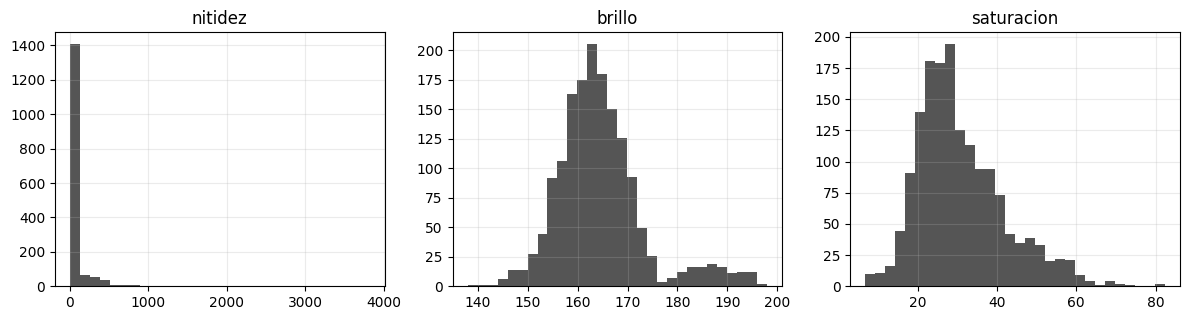

Imágenes muy borrosas (candidatas a recapturar):


,id_fruto,vista,nitidez


Imágenes duplicadas exactas:


,id_fruto,vista,ruta
165,LIM3,0,data\raw\imagenes\L1_20261006_LIM3_0.jpeg
167,LIM3,270,data\raw\imagenes\L1_20261006_LIM3_270.jpeg
240,LIM53,0,data\raw\imagenes\L1_20261006_LIM53_0.jpeg
241,LIM53,180,data\raw\imagenes\L1_20261006_LIM53_180.jpeg
242,LIM53,270,data\raw\imagenes\L1_20261006_LIM53_270.jpeg
243,LIM53,90,data\raw\imagenes\L1_20261006_LIM53_90.jpeg
244,LIM53,pedunculo,data\raw\imagenes\L1_20261006_LIM53_pedunculo....
245,LIM54,0,data\raw\imagenes\L1_20261006_LIM54_0.jpeg
246,LIM54,180,data\raw\imagenes\L1_20261006_LIM54_180.jpeg
247,LIM54,270,data\raw\imagenes\L1_20261006_LIM54_270.jpeg


In [ ]:
met = eda.calcular_metricas_imagenes(imgs, max_imgs=None)
print("Ilegibles:", int((~met.legible).sum()), "| Duplicadas:", int(met.duplicada.sum()))
print("Resoluciones:", met.groupby(["ancho", "alto"]).size().to_dict())
met["borrosa"] = eda.marcar_atipicas(met, "nitidez") & (met["nitidez"] < met["nitidez"].median())
fig, axs = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, col in zip(axs, ["nitidez", "brillo", "saturacion"]):
    ax.hist(met[col].dropna(), bins=30, color="#555"); ax.set_title(col)
plt.tight_layout(); plt.show()
print("Imágenes muy borrosas (candidatas a recapturar):")
display(met[met.borrosa][["id_fruto", "vista", "nitidez"]])
print("Imágenes duplicadas exactas:")
display(met[met.duplicada][["id_fruto", "vista", "ruta"]])

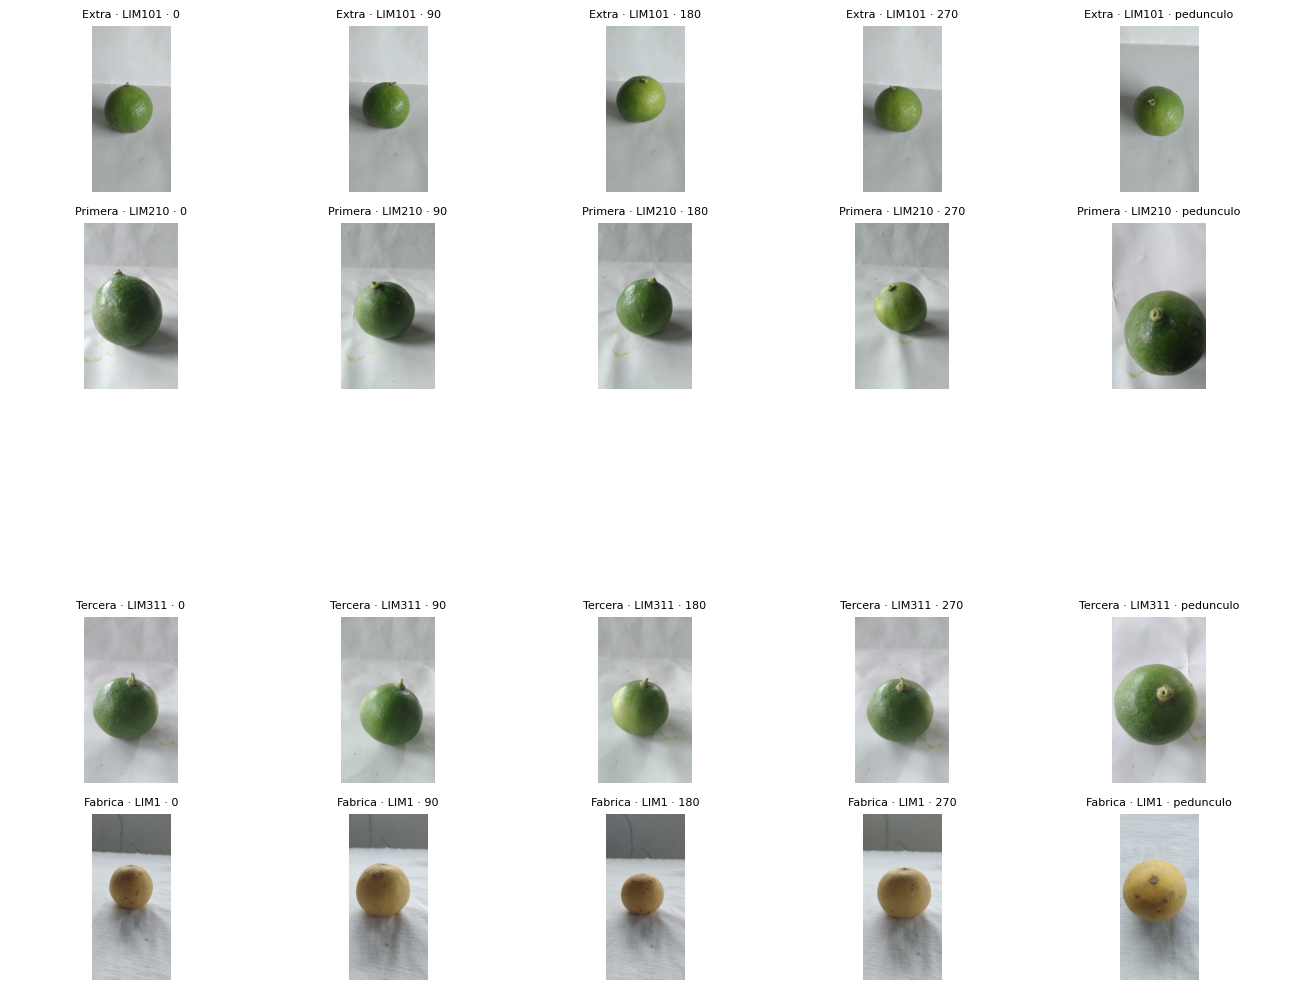

In [ ]:
# Muestra visual: las 5 vistas de un fruto por categoría
fig, axs = plt.subplots(5, 5, figsize=(13, 10))
for i, cat in enumerate(eda.CATEGORIAS):
    f = frutos[(frutos.cat == cat) & frutos.completo].head(1)
    if f.empty: [a.axis("off") for a in axs[i]]; continue
    idf = f.iloc[0]["id_fruto"]
    for j, v in enumerate(eda.__dict__.get("VISTAS", ["0", "90", "180", "270", "pedunculo"])):
        ax = axs[i, j]; ax.axis("off")
        r = imgs[(imgs.id_fruto == idf) & (imgs.vista == v)]
        if len(r):
            p = Path(r.iloc[0]["ruta"]); p = p if p.is_absolute() else ROOT / p
            ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{cat} · {idf} · {v}", fontsize=8)
plt.tight_layout(); plt.show()

## 8. Riesgo de atajos (leakage de contexto)
Si la categoría se puede predecir por **lote/fecha** o por **brillo de la sesión**, el modelo podría aprender el contexto y no el fruto. Qué buscar: V de Cramér cercano a 1 y brillo/nitidez muy distintos entre lotes → controlar iluminación (carta de color) y no usar lote/fecha como entrada.

V de Cramér categoría ~ lote: 1.00  (0 = independiente, 1 = totalmente asociado)
V de Cramér categoría ~ fecha: 1.00  (0 = independiente, 1 = totalmente asociado)

Brillo y nitidez medios por lote (diferencias grandes = iluminación distinta entre sesiones):


,brillo,nitidez,saturacion
lote,,,
L1,166.5,196.4,26.0
L2,162.2,17.8,39.4
L3,165.2,13.5,27.1


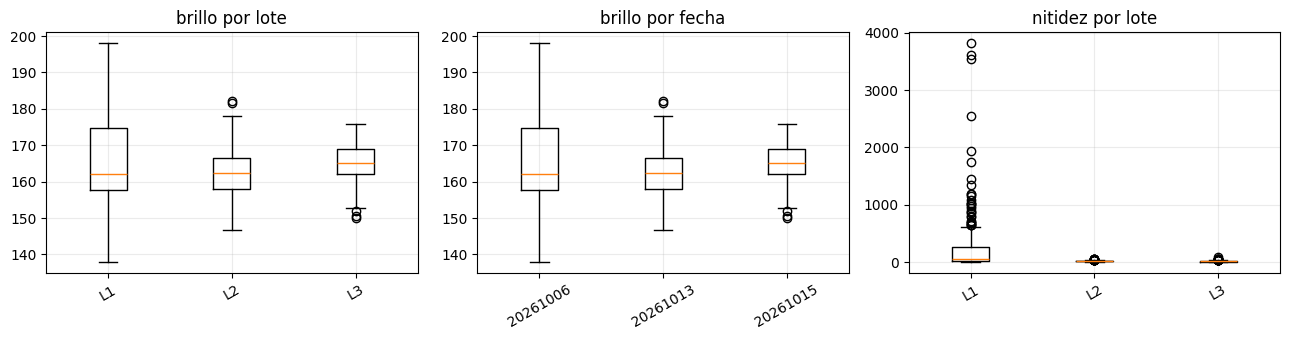

In [ ]:
for col in ["lote", "fecha"]:
    print(f"V de Cramér categoría ~ {col}: {eda.asociacion_categoria_metadato(frutos, col):.2f}  (0 = independiente, 1 = totalmente asociado)")
m2 = met.merge(frutos[["id_fruto", "cat"]], on="id_fruto", how="left")
print("\nBrillo y nitidez medios por lote (diferencias grandes = iluminación distinta entre sesiones):")
display(m2.groupby("lote")[["brillo", "nitidez", "saturacion"]].mean().round(1))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (by, col) in zip(axs, [("lote", "brillo"), ("fecha", "brillo"), ("lote", "nitidez")]):
    grupos = sorted(m2[by].dropna().unique())
    ax.boxplot([m2.loc[m2[by] == g, col] for g in grupos], labels=grupos)
    ax.set_title(f"{col} por {by}"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 9. Vista previa de la partición 70/15/15
**No es la partición oficial** (esa se genera una sola vez y se congela). Sirve para verificar que, al partir por fruto y estratificar por categoría, cada subconjunto conserve todas las categorías, lotes y fechas.

In [ ]:
part = eda.vista_previa_particion(frutos, semilla=0)
display(pd.crosstab(part["cat"], part["subset"]).reindex(eda.CATEGORIAS)[["train", "val", "test"]])
for col in ["lote", "fecha"]:
    t = pd.crosstab(part[col], part["subset"])[["train", "val", "test"]]
    print(f"\n{col}: " + ("OK, todos presentes en los 3 subconjuntos" if (t > 0).all().all() else "⚠ hay valores ausentes en algún subconjunto"))
    display(t)

subset,train,val,test
cat,,,
Extra,76.0,16.0,17.0
Primera,71.0,15.0,15.0
Segunda,NaN,NaN,NaN
Tercera,7.0,2.0,1.0
Fabrica,70.0,15.0,15.0



lote: OK, todos presentes en los 3 subconjuntos


subset,train,val,test
lote,,,
L1,70,15,15
L2,76,16,17
L3,78,17,16



fecha: OK, todos presentes en los 3 subconjuntos


subset,train,val,test
fecha,,,
20261006,70,15,15
20261013,76,16,17
20261015,78,17,16


## 10. Hallazgos y decisiones (completar tras correr con datos reales)

| # | Hallazgo | Evidencia (celda) | Decisión / acción |
|---|---|---|---|
| 1 | ¿Se cumplen las cuotas por categoría? | §3 | |
| 2 | ¿Hay ≥3 lotes y ≥4 fechas, sin concentración por categoría? | §4 | |
| 3 | ¿Etiquetas inconsistentes con el calibre? ¿Cuántas y por qué? | §5 | |
| 4 | ¿% de frutos fronterizos? ¿Impacto en el MAE objetivo? | §5 | |
| 5 | ¿Capturas incompletas, borrosas o duplicadas? | §2, §7 | |
| 6 | ¿Riesgo de atajo por lote/fecha/brillo? | §8 | |
| 7 | ¿La partición 70/15/15 por fruto conserva todas las categorías/lotes/fechas? | §9 | |